
# Multi-Class Benchmark Classification Pipeline

## 1. Project Overview

### Objective
The objective of this project is to build and evaluate supervised machine learning classification models using the Iris dataset.

### Models Used
1. Logistic Regression
2. Decision Tree Classifier

### Technologies Used
- Python
- Pandas
- NumPy
- Scikit-Learn
- Seaborn
- Matplotlib

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-Score

### Dataset
Iris Dataset – A multi-class classification dataset containing measurements of iris flowers belonging to three different species.



## 2. Import Required Libraries

In this section, we import the Python libraries required for data manipulation, visualization, preprocessing, model training, and evaluation.


In [1]:

# Import libraries for data manipulation and numerical operations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import preprocessing and dataset splitting utilities
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Configure visualization style
sns.set_theme(style="whitegrid")

# Display plots directly inside the Jupyter Notebook
%matplotlib inline



## 3. Load the Dataset

In this section, we load the Iris dataset from the CSV file using Pandas.

The dataset contains measurements of iris flowers belonging to three different species: Setosa, Versicolor, and Virginica.

We will store the dataset in a Pandas DataFrame for further exploration and preprocessing.


In [2]:

# Load the Iris dataset from the CSV file
# The dataset is stored inside the Dataset folder
df = pd.read_csv("../Dataset/iris.csv")

# Display the first five rows to inspect the loaded dataset
df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



### 3.1 Dataset Overview

Let's examine the structure of the dataset to understand its dimensions, column names, data types, and memory usage.


In [3]:

# Display the number of rows and columns in the dataset
print("Dataset Shape:", df.shape)

# Display the column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display information about column data types and non-null values
print("\nDataset Information:")
df.info()


Dataset Shape: (150, 5)

Column Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB



### 3.2 Statistical Summary

Generate descriptive statistics to understand the distribution of numerical features in the dataset.


In [4]:

# Generate descriptive statistics for numerical columns
df.describe()


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



### 3.3 Initial Dataset Observations

Based on the initial inspection of the Iris dataset, the following observations were made:

1. The dataset contains 150 observations and 5 columns.
2. Four columns represent numerical flower measurements, while the species column represents the target variable.
3. All numerical features contain valid values, with no missing observations.
4. The numerical features have different ranges and distributions.
5. The dataset is suitable for developing a multi-class classification model.

These observations provide an initial understanding of the dataset before performing exploratory data analysis.



## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset through statistical summaries and visualizations.

In this section, we will examine the distribution of flower species and explore the relationships between different numerical features.



### 4.1 Distribution of Flower Species

First, let's examine the number of observations belonging to each flower species.

This will help us understand the class distribution and determine whether the dataset is balanced.


Number of observations per species:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


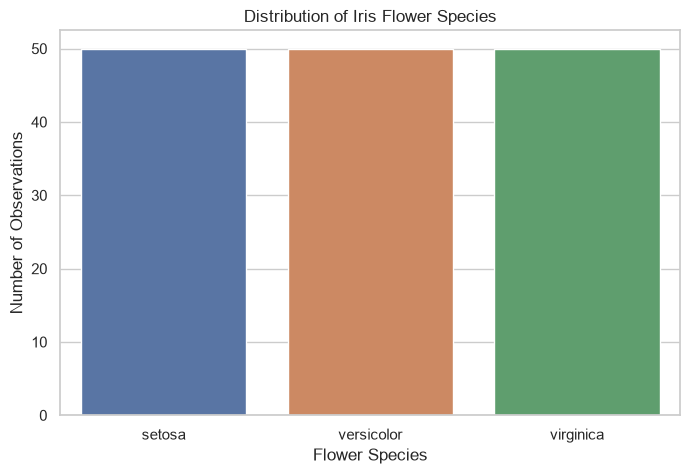

In [5]:

# Count the number of observations for each flower species
species_counts = df["species"].value_counts()

# Display the species distribution
print("Number of observations per species:")
print(species_counts)

# Visualize the distribution of flower species
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species", hue="species", legend=False)

# Add labels and title to the plot
plt.title("Distribution of Iris Flower Species")
plt.xlabel("Flower Species")
plt.ylabel("Number of Observations")

# Display the plot
plt.show()



#### Observations

1. The Iris dataset contains 50 observations for each of the three species.
2. Each species represents approximately 33.33% of the total dataset.
3. The dataset is perfectly balanced across all three classes.
4. No class imbalance handling techniques are required for this dataset.
5. Stratified sampling can be used during train-test splitting to maintain equal class proportions.



### 4.2 Distribution of Numerical Features

Histograms help us understand the distribution and frequency of numerical feature values.

We will plot histograms for all four numerical features to examine their spread, concentration, and distribution patterns.


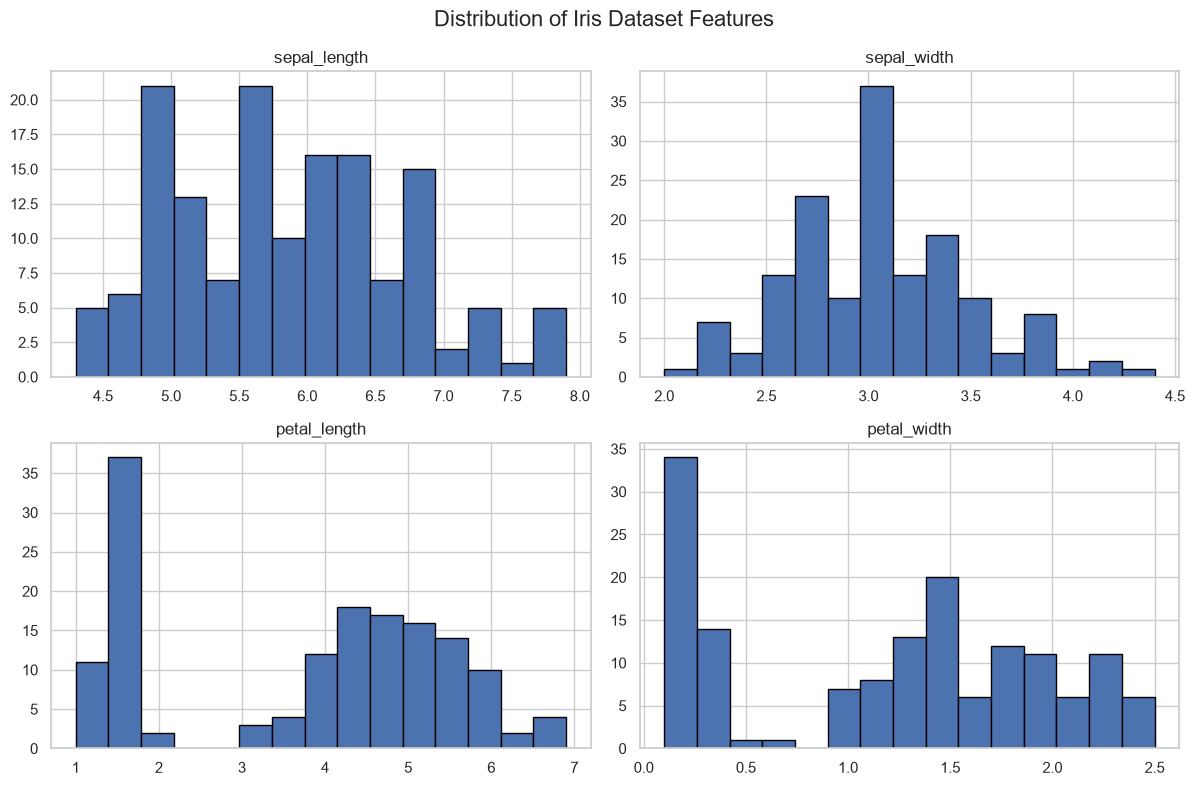

In [6]:

# Select the numerical features for visualization
numerical_features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

# Create histograms for all numerical features
df[numerical_features].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

# Add an overall title to the figure
plt.suptitle("Distribution of Iris Dataset Features", fontsize=16)

# Adjust spacing between subplots
plt.tight_layout()

# Display the histograms
plt.show()



#### Observations from Feature Distributions

1. Sepal length shows a relatively wide distribution, with values ranging from approximately 4.3 to 7.9.
2. Sepal width has a more concentrated distribution, with most observations falling between 2.8 and 3.3.
3. Petal length exhibits distinct groups of values, suggesting its potential importance in distinguishing flower species.
4. Petal width also shows noticeable groupings, indicating that it may be an informative feature for classification.
5. The numerical features have different ranges and distributions, supporting the need for feature scaling before model training.

Overall, petal length and petal width appear to show more distinct groupings than the sepal measurements.



### 4.3 Pairplot: Relationships Between Features

A pairplot visualizes the pairwise relationships between numerical features in the dataset.

It displays scatter plots for relationships between different features and histograms or density plots along the diagonal.

By using the species column as the hue parameter, we can identify how the three flower species are distributed across different feature combinations.


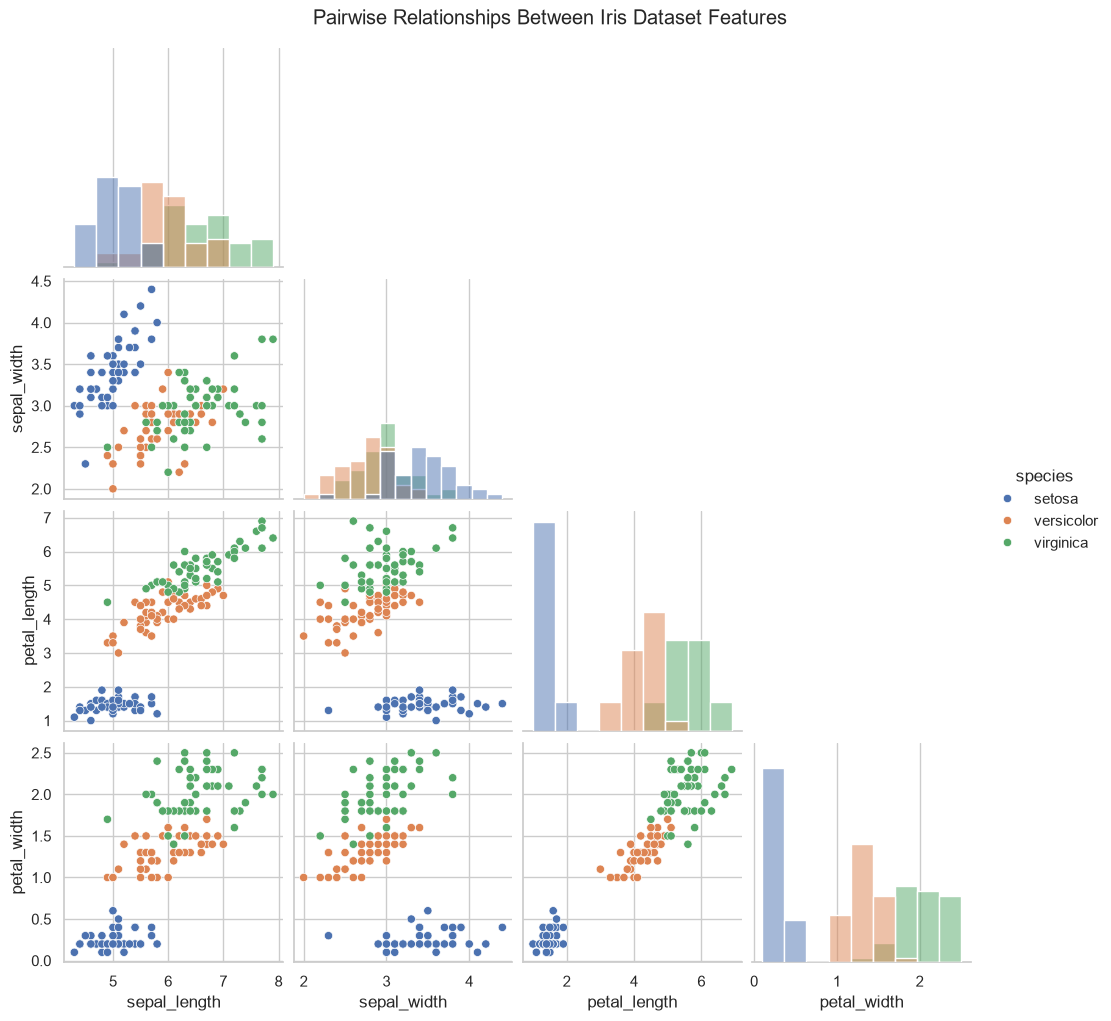

In [7]:

# Create a pairplot to visualize relationships between numerical features
# Different colors represent the three Iris flower species
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist",
    corner=True
)

# Add a title to the pairplot
plt.suptitle(
    "Pairwise Relationships Between Iris Dataset Features",
    y=1.02
)

# Display the pairplot
plt.show()



#### Observations from Pairplot

1. Setosa forms clearly separated clusters from the other two species.
2. Versicolor and Virginica show some overlap in their feature distributions.
3. Petal length and petal width provide better separation between species compared to sepal measurements.
4. The petal measurements reveal distinct clusters, making them useful features for multi-class classification.

Overall, the pairplot indicates that petal measurements are particularly informative for distinguishing Iris flower species.



### 4.4 Correlation Heatmap

Correlation measures the strength and direction of the relationship between numerical features.

The correlation coefficient ranges from -1 to +1:

- +1 indicates a perfect positive correlation.
- -1 indicates a perfect negative correlation.
- 0 indicates no linear correlation.

We will use a heatmap to visualize the correlation between the numerical features of the Iris dataset.


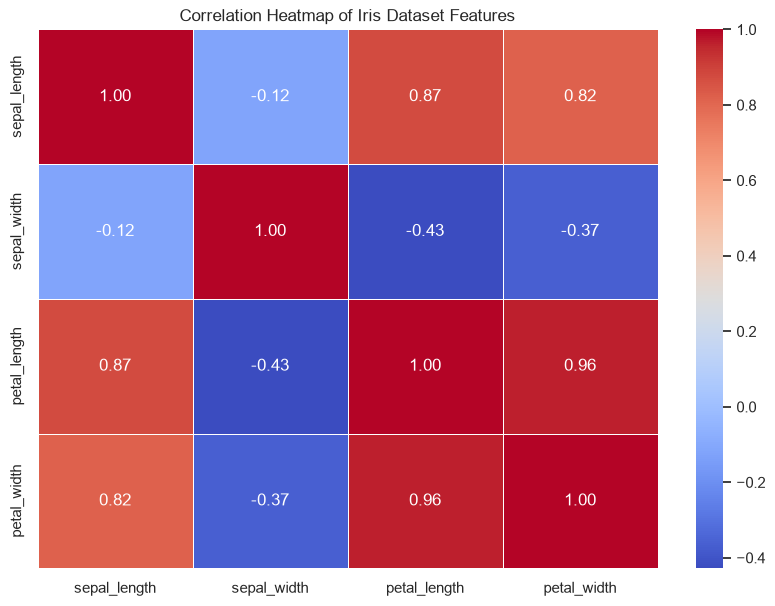

In [8]:

# Select numerical columns to calculate their correlation
# The species column is excluded because it contains categorical values
correlation_matrix = df.select_dtypes(include=np.number).corr()

# Create a figure for the correlation heatmap
plt.figure(figsize=(10, 7))

# Generate the heatmap with correlation values displayed
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

# Add a title to the heatmap
plt.title("Correlation Heatmap of Iris Dataset Features")

# Display the heatmap
plt.show()



#### Observations from Correlation Heatmap

1. Petal length and petal width have a very strong positive correlation of 0.96.
2. Sepal length and petal length show a strong positive correlation of 0.87.
3. Sepal width and sepal length have a weak negative correlation of -0.12.
4. Sepal width and petal length have a moderate negative correlation of -0.43.
5. Sepal width and petal width show a negative correlation of -0.37.

Overall, petal length and petal width exhibit the strongest relationship among the numerical features. These findings suggest that petal measurements may be particularly useful for Iris species classification.
